# WDI2 — Bangladesh's Industrial Transformation in Comparative Asian Perspective

**Scope:** World Development Indicators only. This notebook does not use UNCTAD, Comtrade, BACI, or product-level trade records.

**Purpose:** Rebuild the WDI workflow with transparent data validation, indicator-level coverage checks, descriptive comparisons, defensible panel diagnostics, Bangladesh's historical-versus-current comparison, and a documented list of additional WDI indicators.

## Research framing

The aggregate WDI data can assess whether Bangladesh's macroeconomic and industrial indicators are consistent with selected features of structural transformation. They cannot directly establish product-level industrial relocation or prove a Flying Geese sequence.

**Working title:** *Bangladesh's Industrial Transformation: A Comparative WDI Study in the Context of the Flying Geese Paradigm.*

### Audit issues explicitly addressed

| Audit issue | Treatment in this notebook |
|---|---|
| WDI long format incorrectly deduplicated by country-year | Validate the correct key: country code + series code + year |
| Notebook/data filename case mismatch | Resolve `wdi_data.csv` and the uploaded `wdi_data(1).csv` fallback |
| Missing values and uneven coverage | Convert WDI `..`/blank values to numeric missing values; report coverage per country-indicator |
| Levels correlations treated as co-movement | Compare levels, first differences and growth rates separately |
| Structural-break over-interpretation | Pre-specify candidate years; enforce minimum regime sizes; adjust p-values |
| Annual data seasonally decomposed | No seasonal decomposition is used |
| Female population share interpreted as women's employment | Explicitly label population share as demographic; recommend labour indicators |
| FDI treated as manufacturing upgrading | Separate FDI, gross fixed capital formation, output and export-composition measures |
| High-tech export coverage too short | Report coverage and treat it as a supplementary, short series |
| Cross-sectional dependence ignored | Run Pesaran CD diagnostic on a balanced common sample; qualify downstream inference |
| Unsupported causal language | Interpret associations and predictive diagnostics as non-causal |
| Reproducibility and metadata gaps | Record source, retrieval date, file, sample, indicator codes and references |

## 1. Reproducibility and imports

Run this notebook from the repository root. The preferred input is `wdi_data.csv`. If the uploaded file is named `wdi_data(1).csv`, place it in the repository root or change `DATA_PATH` below.

The notebook never overwrites the raw CSV.

In [1]:
from pathlib import Path
from datetime import date
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

CANDIDATE_PATHS = [
    Path("wdi_data.csv"),
    Path("wdi_data(1).csv"),
    Path("data/wdi_data.csv"),
    Path("data/wdi_data(1).csv"),
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "WDI input not found. Put wdi_data.csv in the repository root "
        "or update CANDIDATE_PATHS."
    )

print(f"Input file: {DATA_PATH.resolve()}")
print(f"Analysis run date: {date.today().isoformat()}")

Input file: C:\BS Project\bd_flying_geese\wdi_data.csv
Analysis run date: 2026-11-12


## 2. Load and validate the raw long-format data

**Problem fixed:** the data are long format, so each country-year can legitimately contain many indicators. The unique observation key is `Country Code`, `Series Code`, and `Time`. We test that key and never drop records using only country and year.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype={"Country Code": "string", "Series Code": "string"})
required = ["Country Name", "Country Code", "Series Name", "Series Code", "Time", "Value"]
missing_columns = sorted(set(required) - set(raw.columns))
assert not missing_columns, f"Required columns missing: {missing_columns}"

df = raw[required].copy()
df["Time"] = pd.to_numeric(df["Time"], errors="coerce")
df["Value_raw"] = df["Value"]
df["Value"] = pd.to_numeric(df["Value"].replace({"..": np.nan, "": np.nan}), errors="coerce")
df = df.dropna(subset=["Country Code", "Series Code", "Time"])
df["Time"] = df["Time"].astype(int)

KEY = ["Country Code", "Series Code", "Time"]
duplicate_rows = df[df.duplicated(KEY, keep=False)].sort_values(KEY)
print(f"Rows loaded: {len(df):,}")
print(f"Unique countries: {df['Country Code'].nunique()}")
print(f"Unique indicators: {df['Series Code'].nunique()}")
print(f"Year range: {df['Time'].min()}–{df['Time'].max()}")
print(f"Duplicate observations on {KEY}: {df.duplicated(KEY).sum()}")
print(f"Non-numeric/missing values: {df['Value'].isna().sum():,}")
display(df.head())
if not duplicate_rows.empty:
    display(duplicate_rows.head(20))
    raise ValueError("Duplicate country-indicator-year keys detected; inspect before proceeding.")

Rows loaded: 16,500
Unique countries: 10
Unique indicators: 25
Year range: 1960–2025
Duplicate observations on ['Country Code', 'Series Code', 'Time']: 0
Non-numeric/missing values: 2,778


,Country Name,Country Code,Series Name,Series Code,Time,Value,Value_raw
0,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1960,57.4743,57.4743123752637
1,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1961,57.9882,57.9882359513306
2,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1962,57.0186,57.0185740229353
3,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1963,57.1467,57.146668173399
4,Bangladesh,BGD,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1964,53.3568,53.3568366475041


## 3. Dataset fingerprint and coverage audit

**Problem fixed:** missingness is not treated as a single dataset-wide percentage. Coverage is reported separately for each country-indicator, with first and last non-missing years. This prevents short series from being mistaken for long historical evidence.

In [3]:
country_map = df[["Country Code", "Country Name"]].drop_duplicates().sort_values("Country Code")
indicator_map = df[["Series Code", "Series Name"]].drop_duplicates().sort_values("Series Code")
assert country_map.groupby("Country Code")["Country Name"].nunique().max() == 1
assert indicator_map.groupby("Series Code")["Series Name"].nunique().max() == 1

coverage = (
    df.groupby(["Country Code", "Country Name", "Series Code", "Series Name"], as_index=False)
      .agg(n_available=("Value", "count"),
           first_year=("Time", lambda s: s[df.loc[s.index, "Value"].notna()].min()),
           last_year=("Time", lambda s: s[df.loc[s.index, "Value"].notna()].max()))
)
coverage["coverage_pct_of_1960_2025"] = coverage["n_available"] / 66 * 100
display(coverage.sort_values(["Series Code", "Country Code"]).head(30))
display(pd.DataFrame({
    "Metric": ["Rows", "Countries", "Indicators", "Years", "Missing values", "Duplicate keys"],
    "Result": [len(df), df["Country Code"].nunique(), df["Series Code"].nunique(),
               f"{df.Time.min()}–{df.Time.max()}", int(df.Value.isna().sum()),
               int(df.duplicated(KEY).sum())]
}))

,Country Code,Country Name,Series Code,Series Name,n_available,first_year,last_year,coverage_pct_of_1960_2025
0,BGD,Bangladesh,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",54,"1,972.0000","2,025.0000",81.8182
25,CHN,China,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",47,"1,979.0000","2,025.0000",71.2121
50,HKG,"Hong Kong SAR, China",BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",56,"1,970.0000","2,025.0000",84.8485
75,IDN,Indonesia,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",56,"1,970.0000","2,025.0000",84.8485
100,JPN,Japan,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",56,"1,970.0000","2,025.0000",84.8485
125,KOR,"Korea, Rep.",BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",56,"1,970.0000","2,025.0000",84.8485
150,MYS,Malaysia,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",56,"1,970.0000","2,025.0000",84.8485
175,PHL,Philippines,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",56,"1,970.0000","2,025.0000",84.8485
200,SGP,Singapore,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",56,"1,970.0000","2,025.0000",84.8485
225,VNM,Viet Nam,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",41,"1,985.0000","2,025.0000",62.1212


,Metric,Result
0,Rows,16500
1,Countries,10
2,Indicators,25
3,Years,1960–2025
4,Missing values,2778
5,Duplicate keys,0


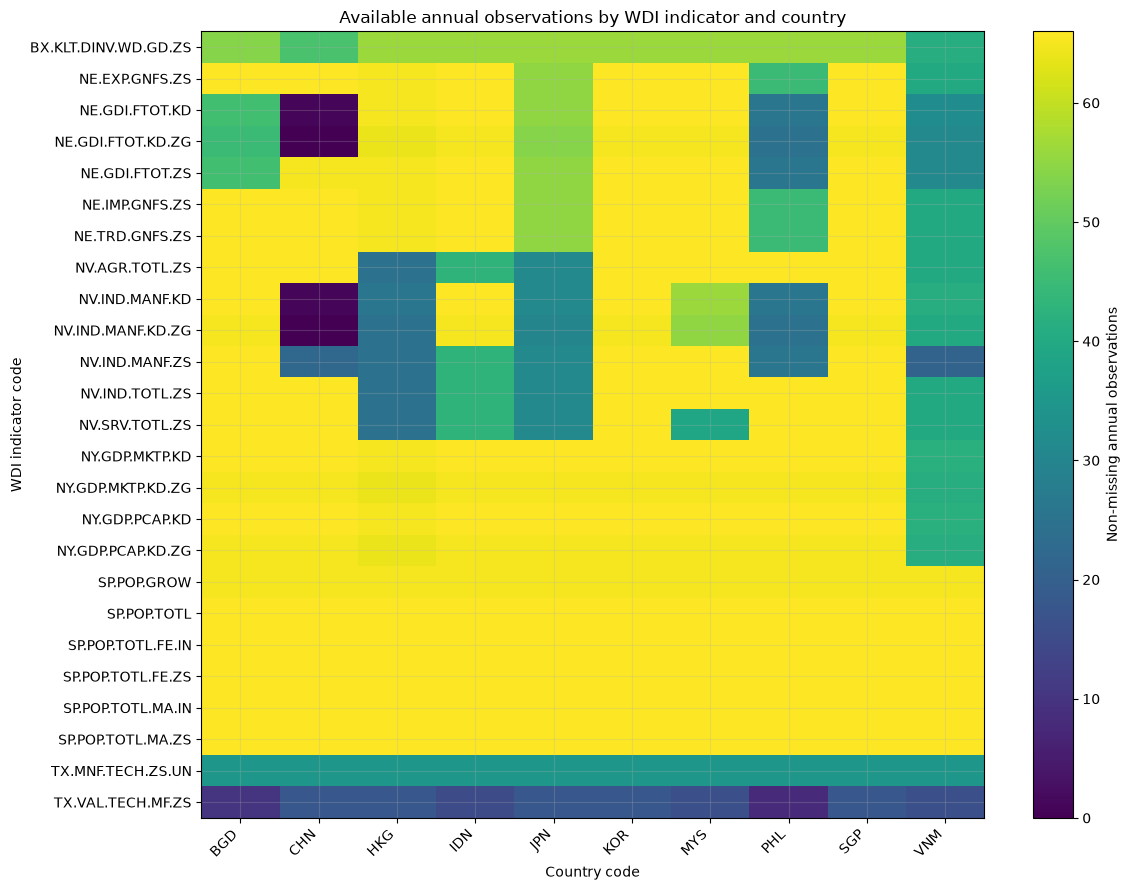

In [4]:
# Heatmap of observed-value coverage by country and indicator
coverage_matrix = coverage.pivot(index="Series Code", columns="Country Code", values="n_available")
fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(coverage_matrix.fillna(0), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(coverage_matrix.columns)), coverage_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(coverage_matrix.index)), coverage_matrix.index)
ax.set_title("Available annual observations by WDI indicator and country")
ax.set_xlabel("Country code")
ax.set_ylabel("WDI indicator code")
fig.colorbar(im, ax=ax, label="Non-missing annual observations")
plt.tight_layout()
plt.show()

## 4. Indicator dictionary and analytical roles

**Problem fixed:** indicators are not interchangeable proxies. Manufacturing output, manufacturing GDP share, FDI, capital formation, and export composition are kept conceptually separate.

The current dataset contains 25 indicators for 10 economies. Indicator codes below are taken from the supplied WDI extract; names are retained as provided in the file.

In [5]:
indicator_dictionary = (
    indicator_map.merge(
        df.groupby("Series Code")["Value"].agg(non_missing="count").reset_index(),
        on="Series Code", how="left"
    )
    .sort_values("Series Code")
)
display(indicator_dictionary)

,Series Code,Series Name,non_missing
0,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",534
1,NE.EXP.GNFS.ZS,Exports of goods and services (% of GDP),601
2,NE.GDI.FTOT.KD,Gross fixed capital formation (constant 2015 US$),489
3,NE.GDI.FTOT.KD.ZG,Gross fixed capital formation (annual % growth),479
4,NE.GDI.FTOT.ZS,Gross fixed capital formation (% of GDP),552
5,NE.IMP.GNFS.ZS,Imports of goods and services (% of GDP),601
6,NE.TRD.GNFS.ZS,Trade (% of GDP),601
7,NV.AGR.TOTL.ZS,"Agriculture, forestry, and fishing, value adde...",535
8,NV.IND.MANF.KD,"Manufacturing, value added (constant 2015 US$)",445
9,NV.IND.MANF.KD.ZG,"Manufacturing, value added (annual % growth)",435


## 5. Construct analysis panels without destroying the source structure

The long file is retained as `df`. A wide panel is generated only for analysis, using a multi-index of country and year and indicator codes as columns. No values are imputed in the primary analysis.

**Problem fixed:** no arbitrary duplicate removal, no silent interpolation, and no forward/backward filling across missing years.

In [6]:
wide = (
    df.pivot(index=["Country Code", "Country Name", "Time"],
             columns="Series Code", values="Value")
      .reset_index()
      .rename(columns={"Time": "year"})
)
wide.columns.name = None
wide = wide.sort_values(["Country Code", "year"]).reset_index(drop=True)
print("Wide panel dimensions:", wide.shape)
display(wide.head())

Wide panel dimensions: (660, 28)


,Country Code,Country Name,year,BX.KLT.DINV.WD.GD.ZS,NE.EXP.GNFS.ZS,NE.GDI.FTOT.KD,NE.GDI.FTOT.KD.ZG,NE.GDI.FTOT.ZS,NE.IMP.GNFS.ZS,NE.TRD.GNFS.ZS,NV.AGR.TOTL.ZS,NV.IND.MANF.KD,NV.IND.MANF.KD.ZG,NV.IND.MANF.ZS,NV.IND.TOTL.ZS,NV.SRV.TOTL.ZS,NY.GDP.MKTP.KD,NY.GDP.MKTP.KD.ZG,NY.GDP.PCAP.KD,NY.GDP.PCAP.KD.ZG,SP.POP.GROW,SP.POP.TOTL,SP.POP.TOTL.FE.IN,SP.POP.TOTL.FE.ZS,SP.POP.TOTL.MA.IN,SP.POP.TOTL.MA.ZS,TX.MNF.TECH.ZS.UN,TX.VAL.TECH.MF.ZS
0,BGD,Bangladesh,1960,NaN,9.9967,NaN,NaN,NaN,9.3073,19.3039,57.4743,"1,485,542,311.6596",NaN,5.3099,6.9738,35.5519,"22,255,159,273.9147",NaN,429.3987,NaN,NaN,"51,828,660.0000","24,878,240.0000",48.0009,"26,950,420.0000",51.9991,NaN,NaN
1,BGD,Bangladesh,1961,NaN,10.7824,NaN,NaN,NaN,11.7000,22.4824,57.9882,"1,607,797,504.5459",8.2297,5.4706,6.7941,35.2176,"23,603,412,614.6943",6.0582,442.7548,3.1104,2.8187,"53,310,348.0000","25,598,804.0000",48.0185,"27,711,544.0000",51.9815,NaN,NaN
2,BGD,Bangladesh,1962,NaN,10.7468,NaN,NaN,NaN,10.8081,21.5548,57.0186,"1,720,417,761.5277",7.0046,5.4487,7.9639,35.0176,"24,890,514,014.5217",5.4530,453.5349,2.4348,2.9039,"54,881,146.0000","26,362,885.0000",48.0363,"28,518,261.0000",51.9637,NaN,NaN
3,BGD,Bangladesh,1963,NaN,9.9835,NaN,NaN,NaN,11.6563,21.6398,57.1467,"1,814,513,481.4379",5.4694,5.3593,7.8046,35.0487,"24,777,039,582.3854",-0.4559,438.4975,-3.3156,2.9149,"56,504,402.0000","27,151,732.0000",48.0524,"29,352,670.0000",51.9476,NaN,NaN
4,BGD,Bangladesh,1964,NaN,10.0284,NaN,NaN,NaN,14.1219,24.1503,53.3568,"1,904,164,340.1991",4.9408,5.5140,10.4230,36.2201,"27,490,816,335.8173",10.9528,472.5264,7.7603,2.9195,"58,178,374.0000","27,964,907.0000",48.0675,"30,213,467.0000",51.9325,NaN,NaN


## 6. Descriptive macroeconomic and industrial transformation trends

The first set of figures plots indicators in their original units. Each graph is a descriptive trajectory, not a causal test. Manufacturing value added in constant 2015 US dollars is an absolute output measure; manufacturing value added as a percentage of GDP is a relative share. These can move in different directions.

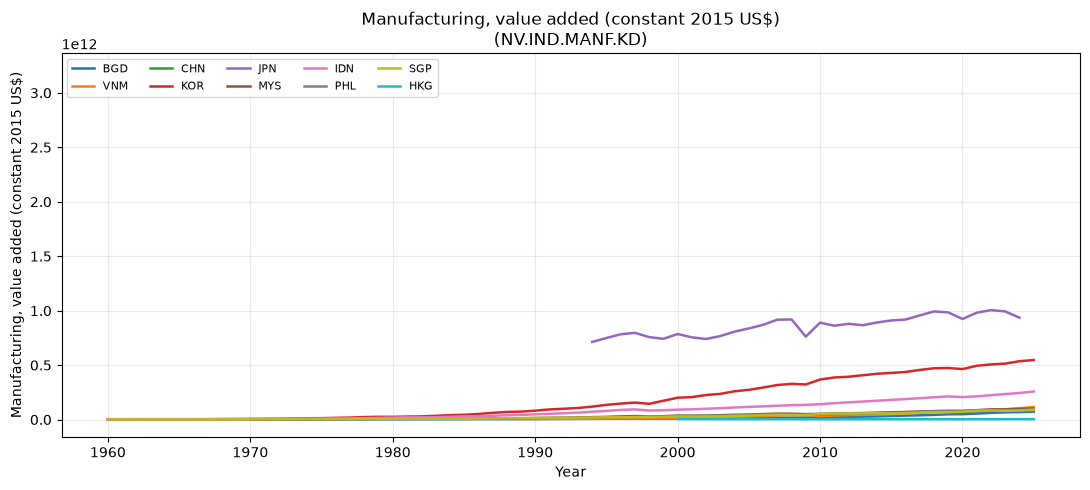

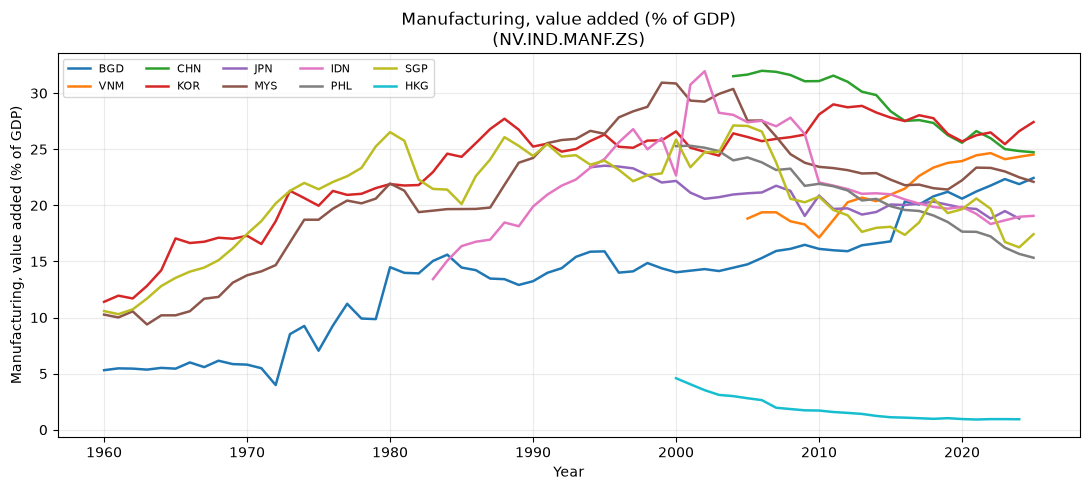

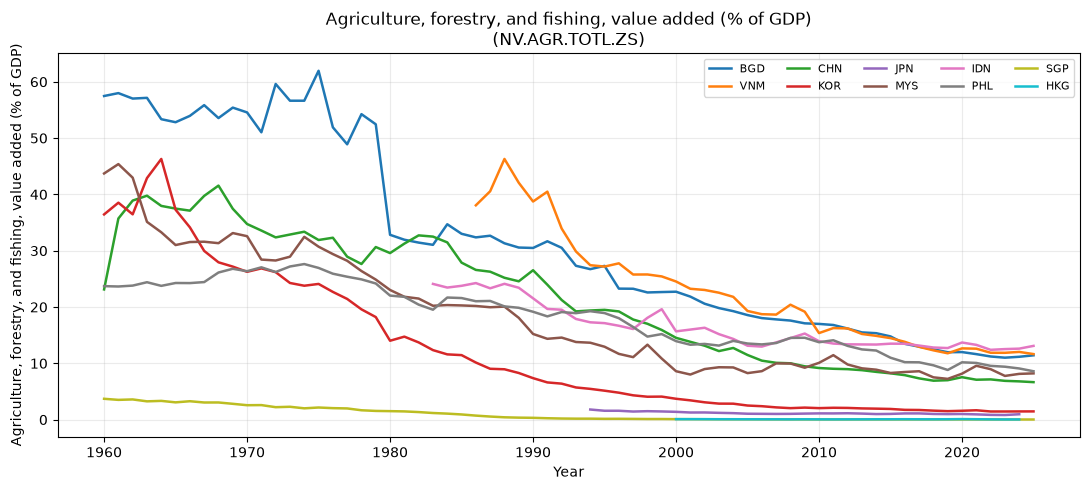

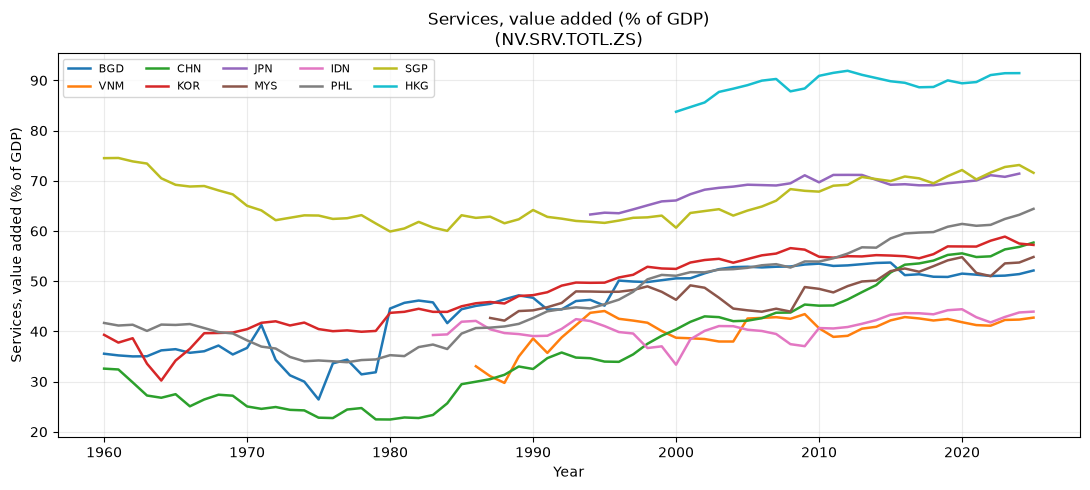

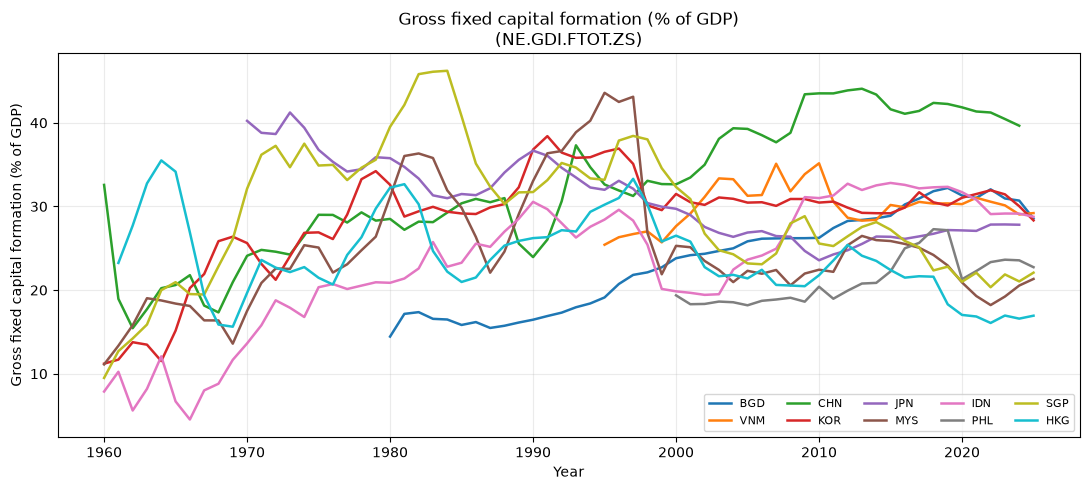

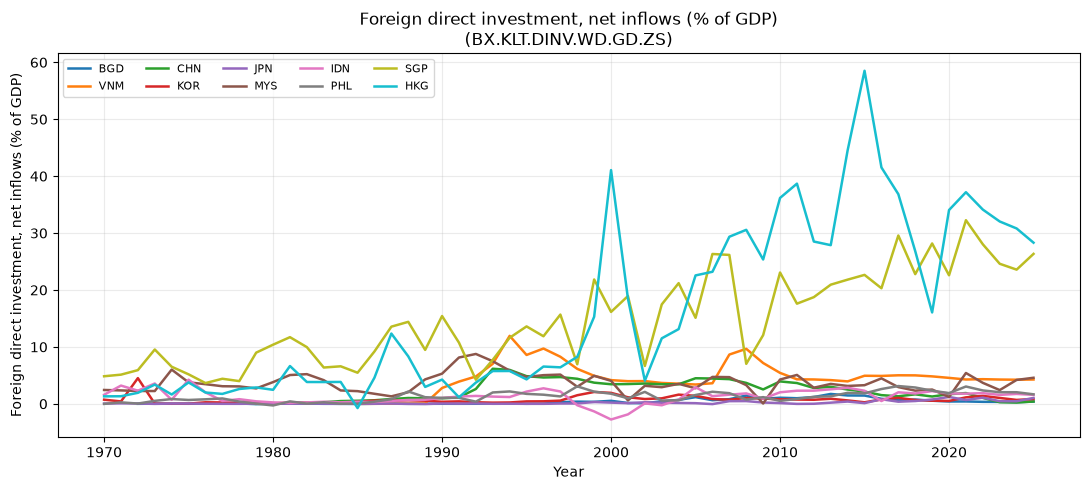

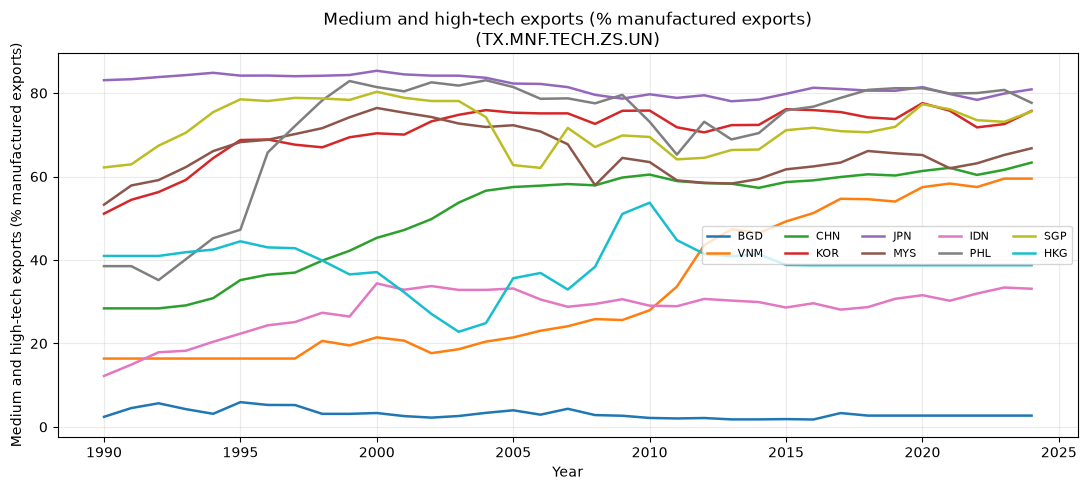

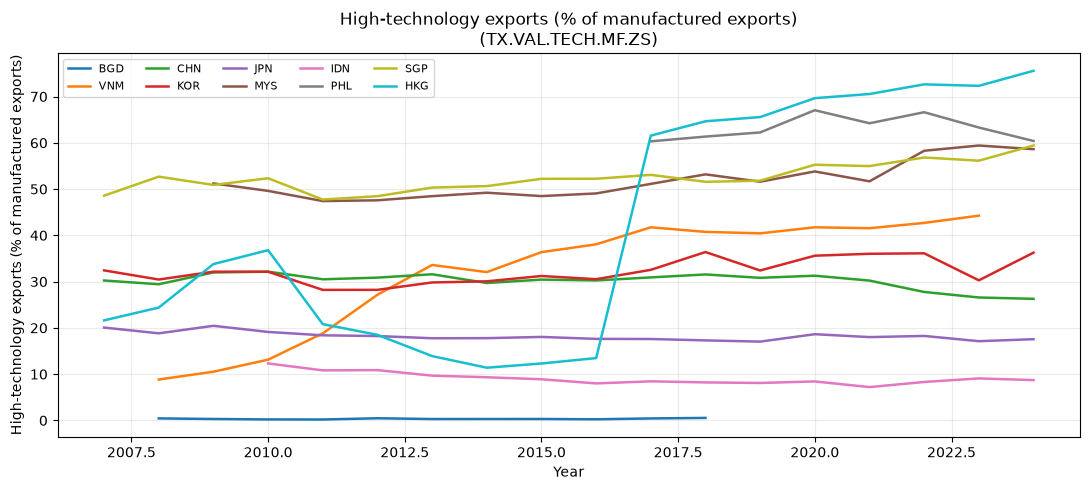

In [7]:
COUNTRIES = ["BGD", "VNM", "CHN", "KOR", "JPN", "MYS", "IDN", "THA", "PHL", "SGP", "HKG"]
COUNTRIES = [c for c in COUNTRIES if c in set(wide["Country Code"])]
PLOT_INDICATORS = [
    "NV.IND.MANF.KD", "NV.IND.MANF.ZS", "NV.AGR.TOTL.ZS",
    "NV.SRV.TOTL.ZS", "NE.GDI.FTOT.ZS", "BX.KLT.DINV.WD.GD.ZS",
    "TX.MNF.TECH.ZS.UN", "TX.VAL.TECH.MF.ZS"
]
for indicator in PLOT_INDICATORS:
    if indicator not in wide.columns:
        continue
    label = indicator_map.set_index("Series Code").loc[indicator, "Series Name"]
    plot_df = wide[wide["Country Code"].isin(COUNTRIES)]
    fig, ax = plt.subplots(figsize=(11, 5))
    for country in COUNTRIES:
        part = plot_df[plot_df["Country Code"] == country].dropna(subset=[indicator])
        if not part.empty:
            ax.plot(part["year"], part[indicator], label=country, linewidth=1.8)
    ax.set_title(f"{label}\n({indicator})")
    ax.set_xlabel("Year")
    ax.set_ylabel(label)
    ax.legend(ncol=5, fontsize=8)
    plt.tight_layout()
    plt.show()

## 7. Bangladesh: historical position versus recent status

**Problem fixed:** current status is not inferred from the final single observation. The comparison uses the first five available observations and the latest five available observations for each indicator, and prints the actual years used. Where the series starts late (especially technology exports), the historical window is explicitly limited by coverage.

For the main macroeconomic indicators, a supplementary fixed-window comparison uses 1960–1969 versus 2021–2025 when enough observations exist.

In [8]:
BGD = wide[wide["Country Code"] == "BGD"].sort_values("year").copy()
assert not BGD.empty, "Bangladesh (BGD) not found."

def endpoint_comparison(country_frame, indicators):
    rows = []
    for ind in indicators:
        if ind not in country_frame.columns:
            continue
        s = country_frame[["year", ind]].dropna().sort_values("year")
        if s.empty:
            continue
        early = s.head(5)
        recent = s.tail(5)
        rows.append({
            "indicator_code": ind,
            "indicator": indicator_map.set_index("Series Code").loc[ind, "Series Name"],
            "early_years": f"{int(early.year.min())}–{int(early.year.max())}",
            "early_mean": early[ind].mean(),
            "recent_years": f"{int(recent.year.min())}–{int(recent.year.max())}",
            "recent_mean": recent[ind].mean(),
            "absolute_change": recent[ind].mean() - early[ind].mean(),
            "relative_change_pct": ((recent[ind].mean()/early[ind].mean())-1)*100
                if early[ind].mean() not in [0, np.nan] and pd.notna(early[ind].mean()) else np.nan,
            "n_early": len(early), "n_recent": len(recent)
        })
    return pd.DataFrame(rows)

bgd_endpoints = endpoint_comparison(BGD, [
    "NV.IND.MANF.KD", "NV.IND.MANF.ZS", "NV.AGR.TOTL.ZS", "NV.SRV.TOTL.ZS",
    "NY.GDP.PCAP.KD", "NE.GDI.FTOT.ZS", "BX.KLT.DINV.WD.GD.ZS",
    "TX.MNF.TECH.ZS.UN", "TX.VAL.TECH.MF.ZS", "SP.POP.TOTL.FE.ZS"
])
display(bgd_endpoints)

,indicator_code,indicator,early_years,early_mean,recent_years,recent_mean,absolute_change,relative_change_pct,n_early,n_recent
0,NV.IND.MANF.KD,"Manufacturing, value added (constant 2015 US$)",1960–1964,"1,706,487,079.8740",2021–2025,"65,130,108,008.8158","63,423,620,928.9418","3,716.6189",5,5
1,NV.IND.MANF.ZS,"Manufacturing, value added (% of GDP)",1960–1964,5.4205,2021–2025,21.9354,16.5149,304.6737,5,5
2,NV.AGR.TOTL.ZS,"Agriculture, forestry, and fishing, value adde...",1960–1964,56.5969,2021–2025,11.2886,-45.3083,-80.0544,5,5
3,NV.SRV.TOTL.ZS,"Services, value added (% of GDP)",1960–1964,35.4112,2021–2025,51.4006,15.9894,45.1535,5,5
4,NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),1960–1964,447.3425,2021–2025,"1,863.5637","1,416.2213",316.5855,5,5
5,NE.GDI.FTOT.ZS,Gross fixed capital formation (% of GDP),1980–1984,16.4011,2021–2025,30.6518,14.2507,86.8886,5,5
6,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",1972–1976,0.0219,2021–2025,0.3545,0.3327,"1,519.5622",5,5
7,TX.MNF.TECH.ZS.UN,Medium and high-tech exports (% manufactured e...,1990–1994,3.9950,2020–2024,2.7076,-1.2874,-32.2254,5,5
8,TX.VAL.TECH.MF.ZS,High-technology exports (% of manufactured exp...,2008–2012,0.3226,2013–2018,0.3632,0.0405,12.5588,5,5
9,SP.POP.TOTL.FE.ZS,"Population, female (% of total population)",1960–1964,48.0351,2021–2025,50.7969,2.7617,5.7494,5,5


In [9]:
# Fixed historical/recent windows, with no imputation.
fixed_rows = []
for ind in PLOT_INDICATORS + ["NY.GDP.PCAP.KD", "NY.GDP.MKTP.KD"]:
    if ind not in BGD.columns:
        continue
    s = BGD[["year", ind]].dropna()
    early = s[s.year.between(1960, 1969)][ind]
    recent = s[s.year.between(2021, 2025)][ind]
    fixed_rows.append({
        "indicator_code": ind,
        "indicator": indicator_map.set_index("Series Code").loc[ind, "Series Name"],
        "1960-1969_mean": early.mean() if len(early) else np.nan,
        "2021-2025_mean": recent.mean() if len(recent) else np.nan,
        "n_early": len(early), "n_recent": len(recent),
        "comparison_status": "Comparable windows" if len(early)>=3 and len(recent)>=3 else "Insufficient window coverage"
    })
bgd_fixed = pd.DataFrame(fixed_rows)
display(bgd_fixed)

,indicator_code,indicator,1960-1969_mean,2021-2025_mean,n_early,n_recent,comparison_status
0,NV.IND.MANF.KD,"Manufacturing, value added (constant 2015 US$)","1,963,525,068.5939","65,130,108,008.8158",10,5,Comparable windows
1,NV.IND.MANF.ZS,"Manufacturing, value added (% of GDP)",5.6133,21.9354,10,5,Comparable windows
2,NV.AGR.TOTL.ZS,"Agriculture, forestry, and fishing, value adde...",55.4572,11.2886,10,5,Comparable windows
3,NV.SRV.TOTL.ZS,"Services, value added (% of GDP)",35.7879,51.4006,10,5,Comparable windows
4,NE.GDI.FTOT.ZS,Gross fixed capital formation (% of GDP),NaN,30.6518,0,5,Insufficient window coverage
5,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",NaN,0.3545,0,5,Insufficient window coverage
6,TX.MNF.TECH.ZS.UN,Medium and high-tech exports (% manufactured e...,NaN,2.7076,0,4,Insufficient window coverage
7,TX.VAL.TECH.MF.ZS,High-technology exports (% of manufactured exp...,NaN,NaN,0,0,Insufficient window coverage
8,NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),454.3752,"1,863.5637",10,5,Comparable windows
9,NY.GDP.MKTP.KD,GDP (constant 2015 US$),"26,964,562,389.3164","319,980,567,116.6542",10,5,Comparable windows


In [10]:
# Data-driven Bangladesh interpretation: compare the earliest available five-year mean
# with the latest available five-year mean. This is descriptive, not a causal test.
for code_id in ["NV.IND.MANF.KD", "NV.IND.MANF.ZS", "NV.AGR.TOTL.ZS",
                "NV.SRV.TOTL.ZS", "NY.GDP.PCAP.KD", "TX.MNF.TECH.ZS.UN"]:
    row = bgd_endpoints[bgd_endpoints["indicator_code"] == code_id]
    if row.empty:
        continue
    r = row.iloc[0]
    if pd.isna(r["early_mean"]) or pd.isna(r["recent_mean"]):
        print(f"{code_id}: insufficient early/recent observations for a valid comparison.")
    elif r["recent_mean"] > r["early_mean"]:
        print(f"{code_id}: higher in {r['recent_years']} (mean={r['recent_mean']:,.3f}) "
              f"than in {r['early_years']} (mean={r['early_mean']:,.3f}).")
    elif r["recent_mean"] < r["early_mean"]:
        print(f"{code_id}: lower in {r['recent_years']} (mean={r['recent_mean']:,.3f}) "
              f"than in {r['early_years']} (mean={r['early_mean']:,.3f}).")
    else:
        print(f"{code_id}: no difference between the two selected period means.")
print("\\nInterpret these as changes in the measured indicator only; do not infer a causal Flying Geese transition.")

NV.IND.MANF.KD: higher in 2021–2025 (mean=65,130,108,008.816) than in 1960–1964 (mean=1,706,487,079.874).
NV.IND.MANF.ZS: higher in 2021–2025 (mean=21.935) than in 1960–1964 (mean=5.421).
NV.AGR.TOTL.ZS: lower in 2021–2025 (mean=11.289) than in 1960–1964 (mean=56.597).
NV.SRV.TOTL.ZS: higher in 2021–2025 (mean=51.401) than in 1960–1964 (mean=35.411).
NY.GDP.PCAP.KD: higher in 2021–2025 (mean=1,863.564) than in 1960–1964 (mean=447.342).
TX.MNF.TECH.ZS.UN: lower in 2020–2024 (mean=2.708) than in 1990–1994 (mean=3.995).
\nInterpret these as changes in the measured indicator only; do not infer a causal Flying Geese transition.


## 8. Levels versus first differences: do not confuse shared trends with co-movement

**Null hypothesis for each correlation test:** \(H_0: \rho=0\) between the two country series for the selected transformation.  
**Alternative:** \(H_1: \rho\ne0\).

- **Levels:** similarity in long-run observed trajectories; vulnerable to common trends and non-stationarity.
- **First differences:** correlation in annual changes; requires both countries to have consecutive observations.
- **Growth rates:** percentage growth in the indicator; used only for strictly positive level series.

The first-difference function below keeps only years that are exactly consecutive within each country. It does not treat a 1990 and 1992 observation as adjacent.

In [11]:
def consecutive_differences(frame, indicator):
    z = frame[["Country Code", "year", indicator]].dropna().sort_values(["Country Code", "year"]).copy()
    z["lag_year"] = z.groupby("Country Code")["year"].shift(1)
    z["diff"] = z.groupby("Country Code")[indicator].diff()
    z.loc[z["year"] - z["lag_year"] != 1, "diff"] = np.nan
    return z

def pairwise_correlations(frame, indicator, country_a="BGD", country_b="VNM"):
    x = frame[frame["Country Code"].isin([country_a, country_b])][["Country Code", "year", indicator]]
    p = x.pivot(index="year", columns="Country Code", values=indicator).dropna()
    out = []
    if {country_a, country_b}.issubset(p.columns) and len(p) >= 5:
        r, pv = stats.spearmanr(p[country_a], p[country_b])
        out.append({"transform":"Levels", "n":len(p), "rho":r, "p_value":pv, "decision": "Reject H0 (association detected)" if pv < 0.05 else "Fail to reject H0"})
    d = consecutive_differences(frame, indicator)
    dp = d.pivot(index="year", columns="Country Code", values="diff").dropna()
    if {country_a, country_b}.issubset(dp.columns) and len(dp) >= 5:
        r, pv = stats.spearmanr(dp[country_a], dp[country_b])
        out.append({"transform":"First differences (consecutive years)", "n":len(dp), "rho":r, "p_value":pv, "decision": "Reject H0 (association detected)" if pv < 0.05 else "Fail to reject H0"})
    return pd.DataFrame(out)

for ind in ["NV.IND.MANF.ZS", "NV.IND.MANF.KD", "TX.MNF.TECH.ZS.UN"]:
    if ind in wide.columns:
        print(f"Bangladesh–Vietnam: {ind}")
        display(pairwise_correlations(wide, ind))

Bangladesh–Vietnam: NV.IND.MANF.ZS


,transform,n,rho,p_value,decision
0,Levels,21,0.8714,0.0000,Reject H0 (association detected)
1,First differences (consecutive years),19,0.0649,0.7918,Fail to reject H0


Bangladesh–Vietnam: NV.IND.MANF.KD


,transform,n,rho,p_value,decision
0,Levels,41,0.9909,0.0000,Reject H0 (association detected)


Bangladesh–Vietnam: TX.MNF.TECH.ZS.UN


,transform,n,rho,p_value,decision
0,Levels,35,-0.5152,0.0015,Reject H0 (association detected)
1,First differences (consecutive years),34,0.0722,0.6849,Fail to reject H0


## 9. Visual comparison of levels and annual changes

The plots show why the same indicator can tell different stories in levels and in year-to-year changes. Annual change plots use only adjacent calendar years.

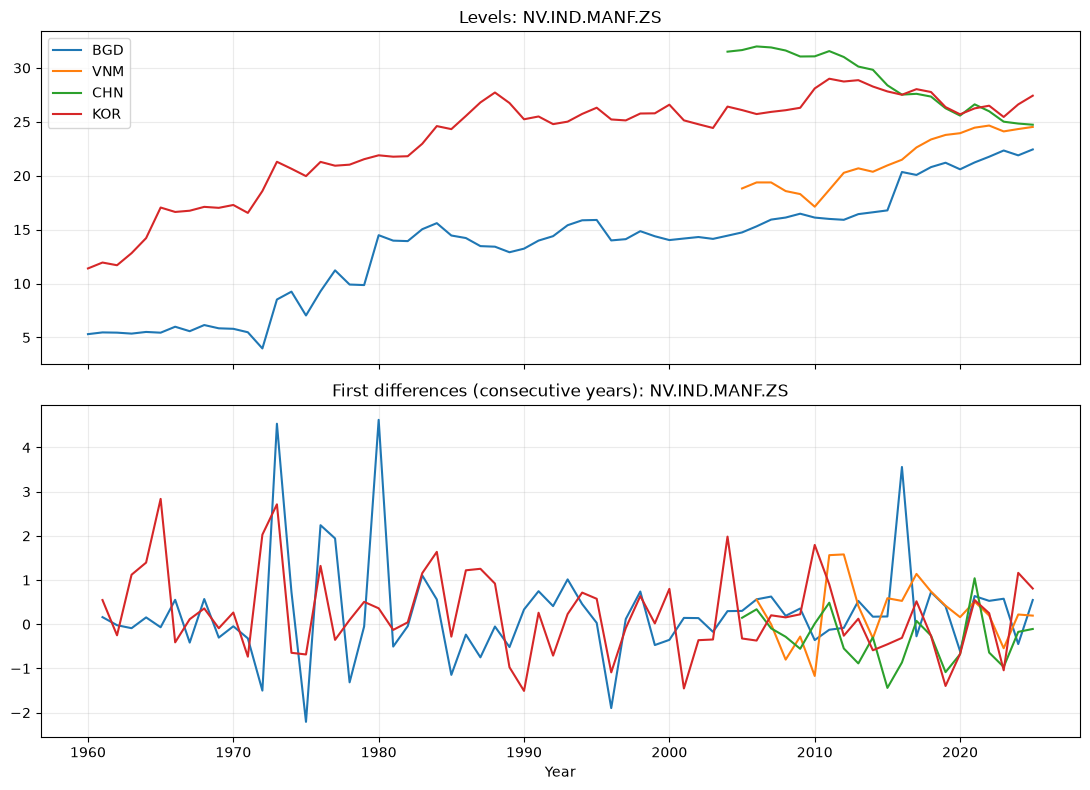

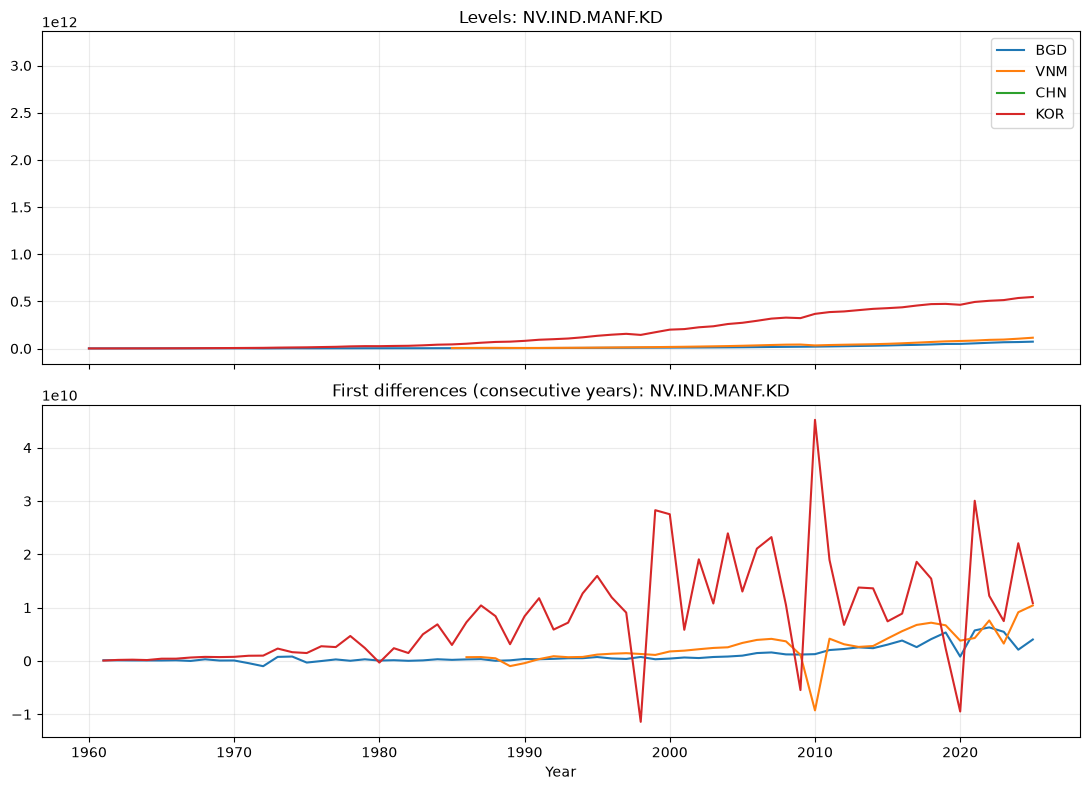

In [12]:
for ind in ["NV.IND.MANF.ZS", "NV.IND.MANF.KD"]:
    if ind not in wide.columns:
        continue
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
    for c in ["BGD", "VNM", "CHN", "KOR"]:
        part = wide[wide["Country Code"] == c].dropna(subset=[ind]).sort_values("year")
        axes[0].plot(part.year, part[ind], label=c)
    axes[0].set_title(f"Levels: {ind}")
    axes[0].legend()
    dif = consecutive_differences(wide, ind)
    for c in ["BGD", "VNM", "CHN", "KOR"]:
        part = dif[(dif["Country Code"] == c) & dif["diff"].notna()]
        axes[1].plot(part.year, part["diff"], label=c)
    axes[1].set_title(f"First differences (consecutive years): {ind}")
    axes[1].set_xlabel("Year")
    plt.tight_layout()
    plt.show()

## 10. Panel diagnostic: Pesaran cross-sectional dependence (CD)

Cross-sectional dependence matters because Asian economies can be exposed to common global demand, financial, commodity, and technology shocks.

**Null hypothesis:** \(H_0\): cross-sectional independence (average pairwise residual correlation is zero).  
**Alternative:** \(H_1\): cross-sectional dependence.

For a balanced panel with \(N\) countries and \(T\) years, the Pesaran CD statistic is:

\[
CD = \sqrt{\frac{2T}{N(N-1)}}\sum_{i<j}\hat{\rho}_{ij}
\]

**Decision rule:** reject \(H_0\) at 5% when the two-sided p-value is below 0.05; otherwise, fail to reject \(H_0\). Failure to reject is not proof of independence.

The code restricts the diagnostic to a balanced common-year sample for the selected indicator. It does not fill missing observations.

In [13]:
def pesaran_cd_balanced(frame, indicator, countries=None):
    countries = countries or sorted(frame["Country Code"].unique())
    p = frame[frame["Country Code"].isin(countries)].pivot(
        index="year", columns="Country Code", values=indicator
    )
    p = p.dropna(axis=0, how="any")
    N, T = p.shape[1], p.shape[0]
    if N < 3 or T < 10:
        return {"indicator":indicator, "N":N, "T":T, "CD":np.nan, "p_value":np.nan,
                "decision":"Not tested: insufficient balanced panel"}
    # Demean each country's series; compute pairwise Pearson correlations.
    q = p - p.mean(axis=0)
    rhos = []
    for i in range(N):
        for j in range(i+1, N):
            rhos.append(q.iloc[:, i].corr(q.iloc[:, j]))
    cd = np.sqrt(2*T/(N*(N-1))) * np.nansum(rhos)
    pval = 2 * stats.norm.sf(abs(cd))
    decision = "Reject H0: evidence of cross-sectional dependence" if pval < 0.05 else "Fail to reject H0"
    return {"indicator":indicator, "N":N, "T":T, "CD":cd, "p_value":pval, "decision":decision}

cd_results = pd.DataFrame([
    pesaran_cd_balanced(wide, ind, COUNTRIES)
    for ind in ["NV.IND.MANF.ZS", "NV.IND.MANF.KD", "NE.GDI.FTOT.ZS",
                "BX.KLT.DINV.WD.GD.ZS", "TX.MNF.TECH.ZS.UN"]
    if ind in wide.columns
])
display(cd_results)

,indicator,N,T,CD,p_value,decision
0,NV.IND.MANF.ZS,10,20,3.4978,0.0005,Reject H0: evidence of cross-sectional dependence
1,NV.IND.MANF.KD,10,1,NaN,NaN,Not tested: insufficient balanced panel
2,NE.GDI.FTOT.ZS,10,25,-1.2233,0.2212,Fail to reject H0
3,BX.KLT.DINV.WD.GD.ZS,10,41,6.4496,0.0000,Reject H0: evidence of cross-sectional dependence
4,TX.MNF.TECH.ZS.UN,10,35,3.9932,0.0001,Reject H0: evidence of cross-sectional dependence


### Interpretation guardrail

If the CD test rejects cross-sectional independence, conventional panel procedures that assume independent cross-sections should not be treated as reliable without robust alternatives. This notebook therefore does **not** mechanically stack IPS/Fisher-ADF, Dumitrescu–Hurlin, or two-way fixed-effects p-values on top of the same dependent panel. A CIPS/CADF or common-correlated-effects implementation should be added only with a validated implementation, suitable critical values, and a documented sample.

The CD statistic above is a diagnostic implementation on a balanced common sample; report the exact `N` and `T` alongside the result.

## 11. Bangladesh structural-break sensitivity: pre-specified years only

This section replaces a blind scan over every possible break year with a small set of historically motivated candidates: 1997, 2008 and 2019. The test is a single-break Chow-type stability test for a linear time trend.

**Null hypothesis:** \(H_0\): intercept and time-trend slope are stable across the candidate year.  
**Alternative:** \(H_1\): at least one coefficient differs before versus after the candidate year.

**Safeguards:** at least 10 observations in each regime; actual calendar years are used; no artificial adjacency is created; p-values are Bonferroni-adjusted across the candidate years. A rejected null indicates a parameter instability around the candidate date, not the cause of the break.

In [14]:
def chow_trend_test(series, break_year, min_regime_n=10):
    z = series.dropna().rename("y").reset_index()
    if "year" not in z.columns:
        z = z.rename(columns={z.columns[0]:"year"})
    z = z.sort_values("year")
    pre = z[z["year"] < break_year]
    post = z[z["year"] >= break_year]
    n1, n2 = len(pre), len(post)
    k = 2  # intercept + linear time trend
    if n1 < min_regime_n or n2 < min_regime_n or (n1+n2) <= 2*k:
        return {"break_year":break_year, "n_pre":n1, "n_post":n2,
                "F":np.nan, "df1":k, "df2":np.nan, "p_value":np.nan, "status":"Skipped: minimum regime size not met"}
    def fit(part):
        X = sm.add_constant(part["year"].astype(float))
        return sm.OLS(part["y"].astype(float), X).fit()
    pooled = fit(z)
    pre_fit, post_fit = fit(pre), fit(post)
    ssr_r = np.sum(pooled.resid**2)
    ssr_u = np.sum(pre_fit.resid**2) + np.sum(post_fit.resid**2)
    df2 = n1+n2-2*k
    F = max(0, ((ssr_r-ssr_u)/k)/(ssr_u/df2))
    pval = stats.f.sf(F, k, df2)
    return {"break_year":break_year, "n_pre":n1, "n_post":n2,
            "F":F, "df1":k, "df2":df2, "p_value":pval, "status":"Tested"}

break_rows = []
if "NV.IND.MANF.ZS" in BGD.columns:
    s = BGD.set_index("year")["NV.IND.MANF.ZS"]
    for yr in [1997, 2008, 2019]:
        break_rows.append(chow_trend_test(s, yr))
breaks = pd.DataFrame(break_rows)
if not breaks.empty:
    m = breaks["p_value"].notna().sum()
    breaks["p_bonferroni"] = (breaks["p_value"] * max(m, 1)).clip(upper=1)
    breaks["decision_5pct_adjusted"] = np.where(
        breaks["p_bonferroni"].notna(),
        np.where(breaks["p_bonferroni"] < .05, "Reject H0", "Fail to reject H0"),
        "Not tested"
    )
display(breaks)

,break_year,n_pre,n_post,F,df1,df2,p_value,status,p_bonferroni,decision_5pct_adjusted
0,1997,37,29,18.9472,2,62.0000,0.0000,Tested,0.0000,Reject H0
1,2008,48,18,4.0864,2,62.0000,0.0215,Tested,0.0430,Reject H0
2,2019,59,7,NaN,2,NaN,NaN,Skipped: minimum regime size not met,NaN,Not tested


## 12. Female population share is not female employment

**Problem fixed:** `SP.POP.TOTL.FE.ZS` describes the female share of the population. It does not measure labour-force participation, employment, or women's employment in industry. It is retained only as a demographic indicator and is not used to support a claim about women's role in manufacturing.

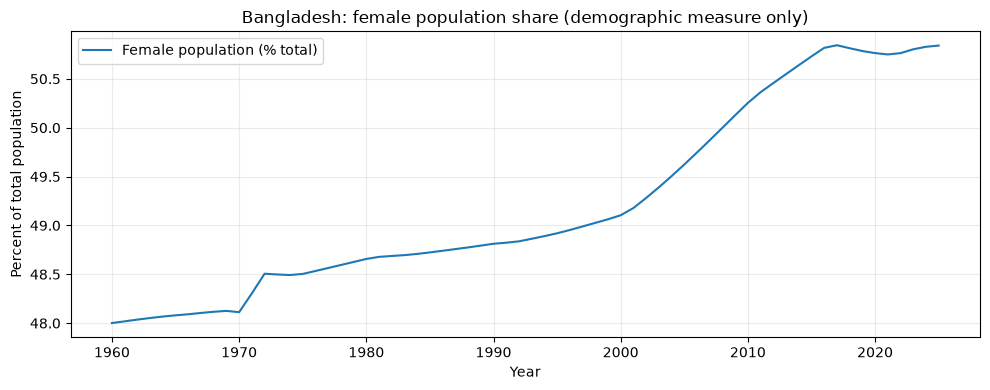

Do not interpret this indicator as female labour-force participation or female manufacturing employment.


In [15]:
if "SP.POP.TOTL.FE.ZS" in BGD.columns:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(BGD.year, BGD["SP.POP.TOTL.FE.ZS"], label="Female population (% total)")
    ax.set_title("Bangladesh: female population share (demographic measure only)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Percent of total population")
    ax.legend()
    plt.tight_layout()
    plt.show()
print("Do not interpret this indicator as female labour-force participation or female manufacturing employment.")

## 13. FDI and domestic capital formation are distinct mechanisms

**Problem fixed:** FDI inflows are not a direct measure of manufacturing investment, technology transfer, supplier development, or productivity. Gross fixed capital formation measures fixed-asset investment in the economy and is not interchangeable with FDI. The World Bank explicitly distinguishes FDI financing from capital formation (see reference [4]).

Use these indicators as separate descriptive dimensions, not as substitutes for one another.

In [16]:
separate_investment = [
    c for c in ["BX.KLT.DINV.WD.GD.ZS", "NE.GDI.FTOT.ZS", "NE.GDI.FTOT.KD"]
    if c in wide.columns
]
display(indicator_map[indicator_map["Series Code"].isin(separate_investment)])

,Series Code,Series Name
132,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)"
594,NE.GDI.FTOT.KD,Gross fixed capital formation (constant 2015 US$)
462,NE.GDI.FTOT.ZS,Gross fixed capital formation (% of GDP)


## 14. Technology-export indicators: coverage and interpretation

**Problem fixed:** high-technology exports have limited historical coverage in this extract. Medium/high-tech exports are broader but still describe the composition of manufactured exports, not domestic technological capability or domestic value added. Both series are shown with their actual coverage, and neither is treated as a direct productivity measure.

In [17]:
tech_coverage = coverage[coverage["Series Code"].isin(
    ["TX.VAL.TECH.MF.ZS", "TX.MNF.TECH.ZS.UN"]
)].sort_values(["Series Code", "Country Code"])
display(tech_coverage[["Country Code","Series Code","n_available","first_year","last_year"]])

,Country Code,Series Code,n_available,first_year,last_year
23,BGD,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
48,CHN,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
73,HKG,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
98,IDN,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
123,JPN,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
148,KOR,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
173,MYS,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
198,PHL,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
223,SGP,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"
248,VNM,TX.MNF.TECH.ZS.UN,35,"1,990.0000","2,024.0000"


## 15. Missingness-aware peer comparison

This table compares Bangladesh with Vietnam and selected Asian benchmarks using each indicator's latest available observation. The year is shown beside every value: latest observations need not refer to the same year across countries. Do not rank countries as if all values were contemporaneous when the years differ.

In [18]:
def latest_country_values(frame, indicators, countries):
    rows = []
    for c in countries:
        part = frame[frame["Country Code"] == c].sort_values("year")
        for ind in indicators:
            if ind not in part.columns:
                continue
            s = part[["year", ind]].dropna()
            if not s.empty:
                r = s.iloc[-1]
                rows.append({"country_code":c, "indicator_code":ind,
                             "latest_year":int(r["year"]), "latest_value":r[ind]})
    return pd.DataFrame(rows)

peer_latest = latest_country_values(
    wide,
    ["NV.IND.MANF.KD", "NV.IND.MANF.ZS", "NY.GDP.PCAP.KD",
     "NE.GDI.FTOT.ZS", "TX.MNF.TECH.ZS.UN", "TX.VAL.TECH.MF.ZS"],
    COUNTRIES
)
display(peer_latest.pivot_table(index="country_code", columns="indicator_code",
                                values="latest_value", aggfunc="first"))
display(peer_latest.pivot_table(index="country_code", columns="indicator_code",
                                values="latest_year", aggfunc="first"))

indicator_code,NE.GDI.FTOT.ZS,NV.IND.MANF.KD,NV.IND.MANF.ZS,NY.GDP.PCAP.KD,TX.MNF.TECH.ZS.UN,TX.VAL.TECH.MF.ZS
country_code,,,,,,
BGD,28.5411,"73,061,195,980.2973",22.4414,"1,984.7329",2.7076,0.5395
CHN,39.6519,"3,202,510,065,357.0000",24.7344,"13,793.2056",63.3469,26.2777
HKG,16.9391,"3,765,114,085.9261",0.9344,"46,450.1893",38.7474,75.5707
IDN,28.7670,"257,518,132,407.6080",19.0651,"4,555.1806",33.1061,8.7110
JPN,27.8136,"935,452,857,944.5439",18.8174,"38,619.3367",80.8892,17.5547
KOR,28.3299,"546,693,781,389.7690",27.4263,"37,469.6600",75.7124,36.2583
MYS,21.3337,"102,250,310,204.0360",22.0957,"12,352.3733",66.7661,58.6277
PHL,22.7365,"85,406,354,578.8858",15.3303,"4,065.8862",77.6605,60.3970
SGP,22.0845,"90,957,176,367.9014",17.4296,"70,683.6833",75.6029,59.4298


indicator_code,NE.GDI.FTOT.ZS,NV.IND.MANF.KD,NV.IND.MANF.ZS,NY.GDP.PCAP.KD,TX.MNF.TECH.ZS.UN,TX.VAL.TECH.MF.ZS
country_code,,,,,,
BGD,2025,2025,2025,2025,2024,2018
CHN,2024,2015,2025,2025,2024,2024
HKG,2025,2025,2024,2025,2024,2024
IDN,2025,2025,2025,2025,2024,2024
JPN,2024,2024,2024,2025,2024,2024
KOR,2025,2025,2025,2025,2024,2024
MYS,2025,2025,2025,2025,2024,2024
PHL,2025,2025,2025,2025,2024,2024
SGP,2025,2025,2025,2025,2024,2024


## 16. What this WDI stage can and cannot conclude

### It can assess
- Whether Bangladesh's manufacturing output and manufacturing share have risen or fallen over time.
- Whether sectoral shares, GDP per capita, capital formation, trade openness and export-composition indicators changed alongside industrialisation.
- Whether Bangladesh's aggregate trajectories resemble or differ from selected Asian economies.
- Whether the observed associations survive basic transformations and data-coverage checks.

### It cannot establish from WDI aggregates alone
- That a specific product or factory relocated from Japan, Korea, China or another economy to Bangladesh.
- That FDI caused technological upgrading.
- That medium/high-tech exports necessarily embody high domestic value added.
- That a statistically selected break was caused by a named historical event.
- That correlation, fixed effects, or Granger-type predictability proves causal influence.

**Next research step beyond this notebook:** use product-level bilateral trade data to calculate RCA, product entry/exit, export-market shares and basket similarity. That is a separate dataset and is intentionally outside this WDI-only notebook.

## 17. Recommended WDI additions (copy-ready indicator codes)

The following are recommended additions to the current extract. Confirm availability for every country and year in the World Bank DataBank before exporting. Some indicators are ILO-modelled estimates and should be labelled accordingly.

### A. Existing indicators — retain these codes

```text
BX.KLT.DINV.WD.GD.ZS
NE.EXP.GNFS.ZS
NE.GDI.FTOT.KD
NE.GDI.FTOT.KD.ZG
NE.GDI.FTOT.ZS
NE.IMP.GNFS.ZS
NE.TRD.GNFS.ZS
NV.AGR.TOTL.ZS
NV.IND.MANF.KD
NV.IND.MANF.KD.ZG
NV.IND.MANF.ZS
NV.IND.TOTL.ZS
NV.SRV.TOTL.ZS
NY.GDP.MKTP.KD
NY.GDP.MKTP.KD.ZG
NY.GDP.PCAP.KD
NY.GDP.PCAP.KD.ZG
SP.POP.GROW
SP.POP.TOTL
SP.POP.TOTL.FE.IN
SP.POP.TOTL.FE.ZS
SP.POP.TOTL.MA.IN
SP.POP.TOTL.MA.ZS
TX.MNF.TECH.ZS.UN
TX.VAL.TECH.MF.ZS
```

### B. High-priority additions

| Indicator | WDI code | Why add it |
|---|---|---|
| Employment in industry (% total employment), modelled ILO | `SL.IND.EMPL.ZS` | Labour absorption in industry; includes manufacturing, construction, mining and utilities |
| Employment in industry, female (% female employment), modelled ILO | `SL.IND.EMPL.FE.ZS` | Gendered industrial employment; not manufacturing-only |\n| Employment in agriculture (% total employment), modelled ILO | `SL.AGR.EMPL.ZS` | Sectoral labour reallocation away from agriculture |\n| Employment in services (% total employment), modelled ILO | `SL.SRV.EMPL.ZS` | Employment absorption in services |
| Female labour-force participation rate (% ages 15+), modelled ILO | `SL.TLF.CACT.FE.ZS` | Female labour supply/participation |
| Female employment-to-population ratio (15+), modelled ILO | `SL.EMP.TOTL.SP.FE.ZS` | Actual employment relative to female working-age population |
| Manufacturing value added (current US$) | `NV.IND.MANF.CD` | Complement to constant-price manufacturing output; do not use for real growth without deflation |
| Manufacturing value added (constant LCU) | `NV.IND.MANF.KN` | Country-specific constant-price output; avoid direct cross-country level comparisons unless converted carefully |
| Gross fixed capital formation, private sector (% GDP) | `NE.GDI.FPRV.ZS` | Separates private fixed investment from total GFCF |
| Manufactured exports (% merchandise exports) | `TX.VAL.MANF.ZS.UN` | Export specialisation in manufactured goods |
| High-technology exports (current US$) | `TX.VAL.TECH.CD` | Absolute scale alongside the high-tech export share; current prices |
| Labour productivity, GDP per person employed (constant 2021 PPP $) | `SL.GDP.PCAP.EM.KD` | Economy-wide productivity proxy; not manufacturing-specific |

**Important:** WDI does not provide a clean, consistent manufacturing-FDI flow measure for all countries and years in this extract. Do not label aggregate FDI as manufacturing FDI.

### C. Copy-ready country codes

Current 10-country sample:
```text
BGD, CHN, HKG, IDN, JPN, KOR, MYS, PHL, SGP, VNM
```

Recommended additions:
```text
THA, TWN
```

- `THA` = Thailand.
- `TWN` = Taiwan (use the World Bank's available economy/territory entry and check availability/recognition in DataBank; its coverage and naming can differ from sovereign-state country lists).
- Keep `HKG` as a distinct financial/trade-centre comparator, not as a conventional manufacturing follower.

### D. DataBank extraction checklist

1. Open World Bank DataBank → World Development Indicators.
2. Paste the indicator codes from section B into Series.
3. Paste country codes from section C into Country.
4. Select annual years; initially target 1990–2025 for labour and technology indicators, and the longest common period available for macroeconomic series.
5. Export CSV and record the retrieval date and metadata version.
6. Merge only on country code + indicator code + year after validating uniqueness.

## 18. References and methodological sources

1. World Bank. *World Development Indicators* (WDI) database and metadata glossary. https://databank.worldbank.org/source/world-development-indicators
2. Pesaran, M. H. (2004). General diagnostic tests for cross section dependence in panels. *CESifo Working Paper No. 1229*. https://www.econ.cam.ac.uk/research-files/repec/cam/pdf/cwpe0435.pdf
3. Pesaran, M. H. (2007). A simple panel unit root test in the presence of cross-section dependence. *Journal of Applied Econometrics, 22*(2), 265–312. https://doi.org/10.1002/jae.951
4. World Bank Data Help Desk. *Is foreign direct investment (FDI) included in gross fixed capital formation?* https://datahelpdesk.worldbank.org/knowledgebase/articles/195312-is-foreign-direct-investment-fdi-included-in-gro
5. World Bank Data Help Desk. *What is the difference between total value added and gross domestic product?* https://datahelpdesk.worldbank.org/knowledgebase/articles/114948-what-is-the-difference-between-total-value-added-a
6. International Labour Organization. *ILOSTAT database* (source for modelled labour-market indicators). https://ilostat.ilo.org/data/

**Citation practice:** cite the WDI indicator code, indicator definition, country sample, year range, and retrieval date in any report that uses these results. Indicator availability and historical values can be revised by the World Bank.

## 19. Export reproducibility tables

The notebook saves derived audit tables only when explicitly run. These outputs are reproducible from the raw CSV and do not alter it.

In [19]:
OUTPUT_DIR = Path("wdi2_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
coverage.to_csv(OUTPUT_DIR / "wdi2_coverage.csv", index=False)
indicator_dictionary.to_csv(OUTPUT_DIR / "wdi2_indicator_dictionary.csv", index=False)
bgd_endpoints.to_csv(OUTPUT_DIR / "wdi2_bangladesh_endpoint_comparison.csv", index=False)
bgd_fixed.to_csv(OUTPUT_DIR / "wdi2_bangladesh_fixed_windows.csv", index=False)
cd_results.to_csv(OUTPUT_DIR / "wdi2_pesaran_cd.csv", index=False)
breaks.to_csv(OUTPUT_DIR / "wdi2_bangladesh_break_sensitivity.csv", index=False)
peer_latest.to_csv(OUTPUT_DIR / "wdi2_peer_latest_values.csv", index=False)
print(f"Saved audit tables to: {OUTPUT_DIR.resolve()}")

Saved audit tables to: C:\BS Project\bd_flying_geese\wdi2_outputs


## Final checklist before citing results

- [ ] Confirm that the input CSV is the intended frozen WDI extract.
- [ ] Record the exact download/retrieval date from the World Bank DataBank.
- [ ] Review the country-indicator coverage table before comparing trends.
- [ ] Use constant-price values for real output growth; do not interpret current-price values as real growth.
- [ ] Keep levels, first differences and growth rates separate.
- [ ] Report \(N\), \(T\), test statistics, p-values, null/alternative hypotheses and decision rules.
- [ ] Treat cross-sectional dependence as a material limitation.
- [ ] Do not interpret structural breaks as causal effects of COVID-19 or policy events.
- [ ] Do not interpret female population share as employment.
- [ ] Do not interpret FDI as manufacturing investment or technological upgrading.
- [ ] Do not claim product-level Flying Geese relocation from aggregate WDI indicators.